<a href="https://colab.research.google.com/github/brandoncabrera707/STA_108_Regression_FinalProject/blob/main/FinalProject_STA108.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
install.packages("corrplot")
library(corrplot)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



In [ ]:
Demographic <- read.table("Demographic.txt")
colnames(Demographic) <-c('ID','County','state','Land_area','total_population','Population_18to34','Population_65',
  'Physicians','beds','Y_i','Graduate_highschool','Graduate_Bachelor','below_poverty','unemployment','capita_income','personal_income','Geographic_region')

attach(Demographic)

head(Demographic)

,ID,County,state,Land_area,total_population,Population_18to34,Population_65,Physicians,beds,Y_i,Graduate_highschool,Graduate_Bachelor,below_poverty,unemployment,capita_income,personal_income,Geographic_region
,<int>,<chr>,<chr>,<int>,<int>,<dbl>,<dbl>,<int>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<int>,<int>
1,1,Los_Angeles,CA,4060,8863164,32.1,9.7,23677,27700,688936,70.0,22.3,11.6,8.0,20786,184230,4
2,2,Cook,IL,946,5105067,29.2,12.4,15153,21550,436936,73.4,22.8,11.1,7.2,21729,110928,2
3,3,Harris,TX,1729,2818199,31.3,7.1,7553,12449,253526,74.9,25.4,12.5,5.7,19517,55003,3
4,4,San_Diego,CA,4205,2498016,33.5,10.9,5905,6179,173821,81.9,25.3,8.1,6.1,19588,48931,4
5,5,Orange,CA,790,2410556,32.6,9.2,6062,6369,144524,81.2,27.8,5.2,4.8,24400,58818,4
6,6,Kings,NY,71,2300664,28.3,12.4,4861,8942,680966,63.7,16.6,19.5,9.5,16803,38658,1


In [ ]:
Demographic2 <- Demographic
Demographic2$Y_i <- log(Demographic$Y_i) # the respone we want
colnames(Demographic2)[10] <- "Log(Y_i)"


#split into regions
region_1 <- Demographic2[Demographic2$Geographic_region == 1,]
region_2 <- Demographic2[Demographic2$Geographic_region == 2,]
region_3 <- Demographic2[Demographic2$Geographic_region == 3,]
region_4 <- Demographic2[Demographic2$Geographic_region == 4,]



n1<-nrow(region_1)
n2<-nrow(region_2)
n3<-nrow(region_3)
n4<-nrow(region_4)


n1
n2
n3
n4


[1] 103

[1] 108

[1] 152

[1] 77

In [ ]:
head(region_1)

,ID,County,state,Land_area,total_population,Population_18to34,Population_65,Phy sicians,beds,Log(Y_i),Graduate_highschool,Graduate_Bachelor,below_poverty,unemployment,capita_income,persona l_income,Geographic_region
,<int>,<chr>,<chr>,<int>,<int>,<dbl>,<dbl>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<int>,<int>
6,6,Kings,NY,71,2300664,28.3,12.4,4861,8942,13.43127,63.7,16.6,19.5,9.5,16803,38658,1
11,11,Philadelphia,PA,135,1585577,29.1,15.2,6641,10494,11.60046,64.3,15.2,16.1,8.0,16721,26512,1
16,16,Middlesex,MA,824,1398468,31.7,12.5,5158,4152,10.48640,84.3,35.4,4.2,7.3,25312,35398,1
17,17,Allegheny,PA,730,1336449,26.2,17.4,5281,8436,10.82349,79.0,22.6,8.7,5.3,20681,27639,1
18,18,Suffolk,NY,911,1321864,27.9,10.8,3021,3904,11.10831,82.2,23.0,3.3,7.0,24262,32071,1
19,19,Nassau,NY,287,1287348,25.7,14.2,6147,5200,10.67367,84.2,30.0,2.5,5.1,31679,40782,1


# Region 1 (Physicans)

In [ ]:
head(region_1)

,ID,County,state,Land_area,total_population,Population_18to34,Population_65,Phy sicians,beds,Log(Y_i),Graduate_highschool,Graduate_Bachelor,below_poverty,unemployment,capita_income,persona l_income,Geographic_region
,<int>,<chr>,<chr>,<int>,<int>,<dbl>,<dbl>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<int>,<int>
6,6,Kings,NY,71,2300664,28.3,12.4,4861,8942,13.43127,63.7,16.6,19.5,9.5,16803,38658,1
11,11,Philadelphia,PA,135,1585577,29.1,15.2,6641,10494,11.60046,64.3,15.2,16.1,8.0,16721,26512,1
16,16,Middlesex,MA,824,1398468,31.7,12.5,5158,4152,10.48640,84.3,35.4,4.2,7.3,25312,35398,1
17,17,Allegheny,PA,730,1336449,26.2,17.4,5281,8436,10.82349,79.0,22.6,8.7,5.3,20681,27639,1
18,18,Suffolk,NY,911,1321864,27.9,10.8,3021,3904,11.10831,82.2,23.0,3.3,7.0,24262,32071,1
19,19,Nassau,NY,287,1287348,25.7,14.2,6147,5200,10.67367,84.2,30.0,2.5,5.1,31679,40782,1


Warning message in cor(region_1[, 4:17]):
“the standard deviation is zero”


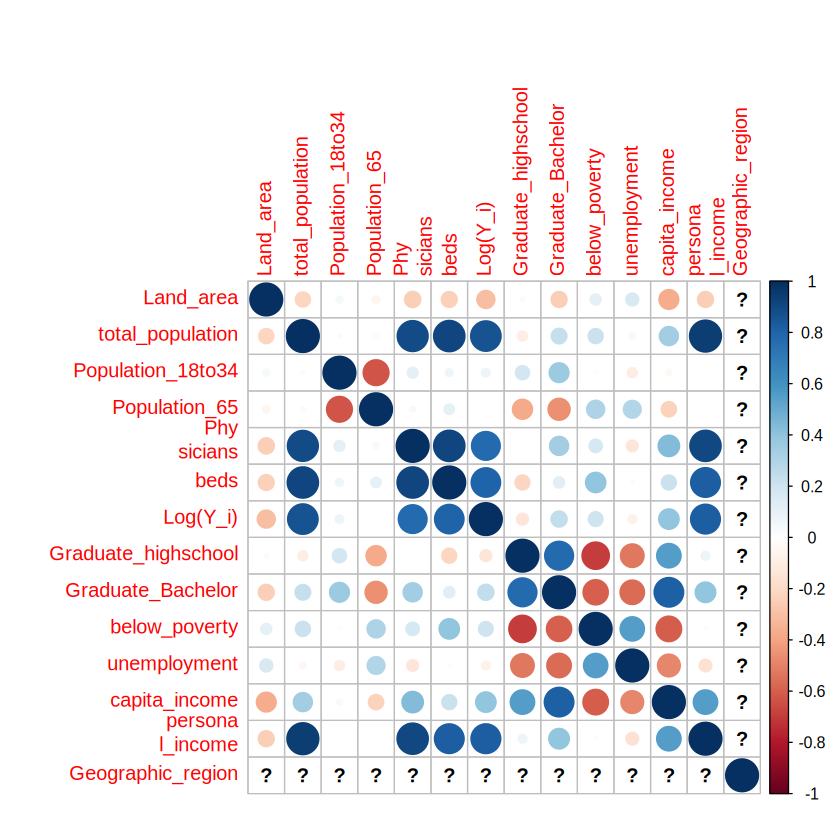

In [ ]:
corrplot(cor(region_1[,4:17])) # see which predictors have the most correlation with response

In [ ]:
# Compute correlation of Log(Y_i) with all numeric predictors
cor_matrix <- cor(region_1[, 4:17], region_1[, "Log(Y_i)"])
cor_matrix

Warning message in cor(region_1[, 4:17], region_1[, "Log(Y_i)"]):
“the standard deviation is zero”


Land_area,-0.3060286240
total_population,0.8625570205
Population_18to34,0.0723089786
Population_65,0.0008715935
Phy sicians,0.7702249597
beds,0.8068340254
Log(Y_i),1.0000000000
Graduate_highschool,-0.1341657961
Graduate_Bachelor,0.2447181614
below_poverty,0.2050836446
unemployment,-0.0724309809


For region 1 we selected physicans as a predictor due to the correlation coefficent of 0.7702 indicating that as the number of phyiscans increases so does the log of total serious crimes increase.

# Regression Fit For Region 1

In [ ]:
#Fit the response to physicians
model_r_1 <- lm(`Log(Y_i)` ~ Physicians, data = region_1)
summary(model_r_1)
anova(model_r_1)


Call:
lm(formula = `Log(Y_i)` ~ Physicians, data = region_1)

Residuals:
     Min       1Q   Median       3Q      Max 
-1.48600 -0.55421 -0.01494  0.50987  2.01263 

Coefficients:
             Estimate Std. Error t value Pr(>|t|)    
(Intercept) 8.618e+00  8.580e-02  100.44   <2e-16 ***
Physicians  5.762e-04  4.748e-05   12.14   <2e-16 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 0.6929 on 101 degrees of freedom
Multiple R-squared:  0.5932,	Adjusted R-squared:  0.5892 
F-statistic: 147.3 on 1 and 101 DF,  p-value: < 2.2e-16


,Df,Sum Sq,Mean Sq,F value,Pr(>F)
,<int>,<dbl>,<dbl>,<dbl>,<dbl>
Physicians,1,70.71653,70.7165317,147.3076,1.907536e-21
Residuals,101,48.48608,0.4800602,NA,NA


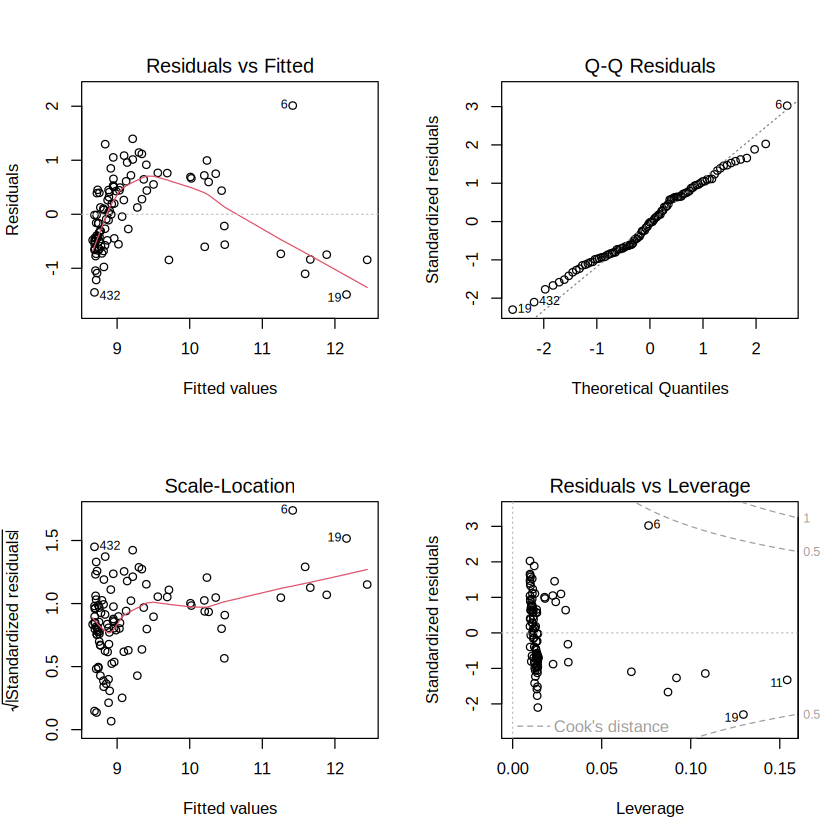

In [ ]:
par(mfrow=c(2,2))

plot(model_r_1)

It is clear that in the Residuals vs Fitted graph that there is a nonlinear relationship. From the Q-Q plot the errors appear normally distributed. From the Scale-Location the variance seems to spread as along the fitted value axis. For the residuals vs leverage most points are well within the cook's distance lines except for observations 6, 11, and 19 getting close to the lines but is nothing to worry about. Due to the non-linear relationship shown in the Residuals vs Fitted graph there it appears appropiate to do a transformation on the Physicans predictor variable

# Region 2

In [ ]:
head(region_2)

,ID,County,state,Land_area,total_population,Population_18to34,Population_65,Phy sicians,beds,Log(Y_i),Graduate_highschool,Graduate_Bachelor,below_poverty,unemployment,capita_income,persona l_income,Geographic_region
,<int>,<chr>,<chr>,<int>,<int>,<dbl>,<dbl>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<int>,<int>
2,2,Cook,IL,946,5105067,29.2,12.4,15153,21550,12.98754,73.4,22.8,11.1,7.2,21729,110928,2
8,8,Wayne,MI,614,2111687,27.4,12.5,3823,9490,12.17550,70.0,13.7,16.9,10.0,17461,36872,2
15,15,Cuyahoga,OH,458,1412140,26.3,15.6,5620,8132,11.20027,74.0,20.1,11.0,5.5,21086,29776,2
25,25,Oakland,MI,873,1083592,27.6,10.9,4020,3254,10.83887,84.6,30.2,4.4,7.3,26884,29131,2
27,27,Hennepin,MN,557,1032431,31.6,11.3,3706,5395,11.18098,88.2,31.6,6.4,4.3,23705,24474,2
28,28,St._Louis,MO,508,993529,26.1,13.1,1194,1056,10.65949,82.3,29.2,4.0,5.1,24219,24062,2


Warning message in cor(region_2[, 4:17]):
“the standard deviation is zero”


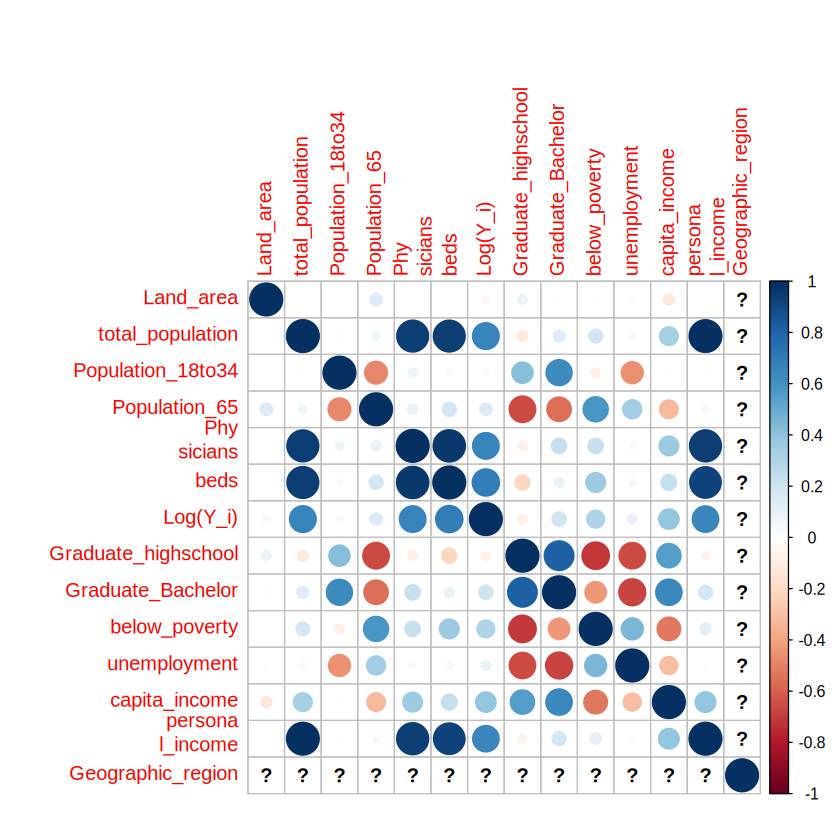

In [ ]:
corrplot(cor(region_2[,4:17])) # see which predictors have the most correlation with response

In [ ]:
# Compute correlation of Log(Y_i) with all numeric predictors
cor_matrix <- cor(region_2[, 4:17], region_2[, "Log(Y_i)"])
cor_matrix

Warning message in cor(region_2[, 4:17], region_2[, "Log(Y_i)"]):
“the standard deviation is zero”


Land_area,-0.04990802
total_population,0.66791550
Population_18to34,0.03995540
Population_65,0.14653743
Phy sicians,0.66081503
beds,0.69191761
Log(Y_i),1.00000000
Graduate_highschool,-0.08033347
Graduate_Bachelor,0.19634329
below_poverty,0.30253339
unemployment,0.09208666


# Region 3 (Personal Income)

In [ ]:
head(region_3)

,ID,County,state,Land_area,total_population,Population_18to34,Population_65,Phy sicians,beds,Log(Y_i),Graduate_highschool,Graduate_Bachelor,below_poverty,unemployment,capita_income,persona l_income,Geographic_region
,<int>,<chr>,<chr>,<int>,<int>,<dbl>,<dbl>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<int>,<int>
3,3,Harris,TX,1729,2818199,31.3,7.1,7553,12449,12.44322,74.9,25.4,12.5,5.7,19517,55003,3
9,9,Dade,FL,1945,1937094,27.1,13.9,6274,8840,12.40789,65.0,18.8,14.2,8.7,17823,34525,3
10,10,Dallas,TX,880,1852810,32.6,8.2,4718,6934,12.27494,77.1,26.3,10.4,6.1,21001,38911,3
21,21,Broward,FL,1209,1255488,25.3,20.7,2456,5543,11.58419,76.8,18.8,7.1,7.4,22355,28066,3
22,22,Bexar,TX,1247,1185394,29.5,9.9,3062,4086,11.79884,72.7,19.7,16.2,6.7,15508,18383,3
24,24,Tarrant,TX,864,1170103,32.2,8.3,1677,3672,11.79430,79.9,24.0,8.2,6.6,18825,22027,3


Warning message in cor(region_3[, 4:17]):
“the standard deviation is zero”


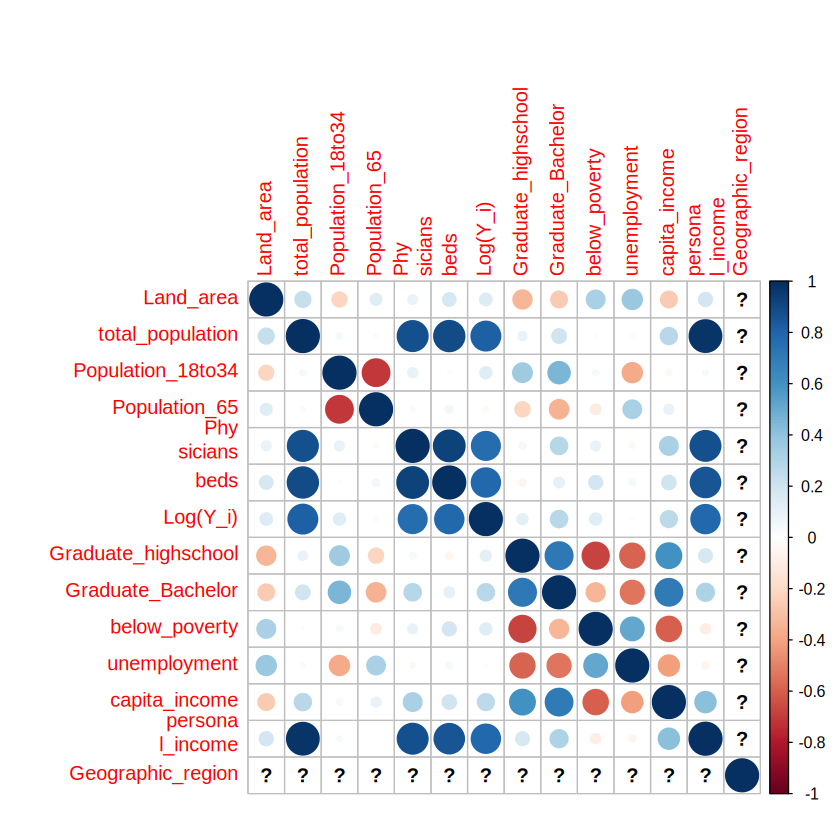

In [ ]:
corrplot(cor(region_3[,4:17])) # see which predictors have the most correlation with response

In [ ]:
# Compute correlation of Log(Y_i) with all numeric predictors
cor_matrix <- cor(region_3[, 4:17], region_3[, "Log(Y_i)"])
cor_matrix

Warning message in cor(region_3[, 4:17], region_3[, "Log(Y_i)"]):
“the standard deviation is zero”


Land_area,0.14532890
total_population,0.81553604
Population_18to34,0.13616901
Population_65,-0.02934348
Phy sicians,0.76894873
beds,0.78782089
Log(Y_i),1.00000000
Graduate_highschool,0.11434752
Graduate_Bachelor,0.27785325
below_poverty,0.13628881
unemployment,0.01904814


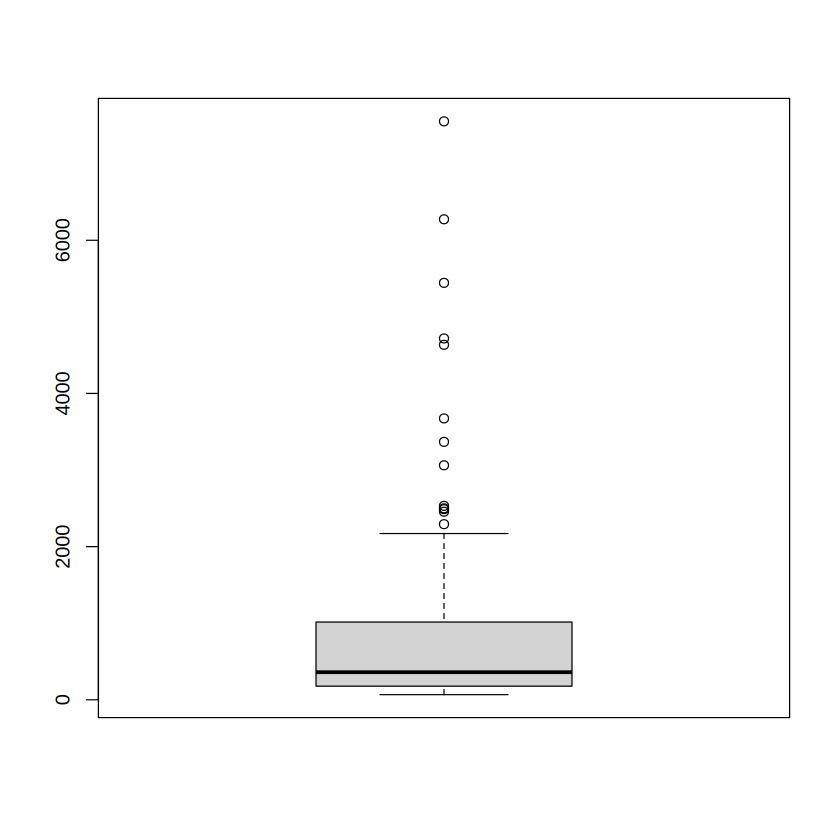

In [ ]:
boxplot(region_3[,8])

Regression Fit 3


# Region 4 (Total Population)

In [ ]:
head(region_4)

,ID,County,state,Land_area,total_population,Population_18to34,Population_65,Physicians,beds,Log(Y_i),Graduate_highschool,Graduate_Bachelor,below_poverty,unemployment,capita_income,personal_income,Geographic_region
,<int>,<chr>,<chr>,<int>,<int>,<dbl>,<dbl>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<int>,<int>
1,1,Los_Angeles,CA,4060,8863164,32.1,9.7,23677,27700,13.44290,70.0,22.3,11.6,8.0,20786,184230,4
4,4,San_Diego,CA,4205,2498016,33.5,10.9,5905,6179,12.06578,81.9,25.3,8.1,6.1,19588,48931,4
5,5,Orange,CA,790,2410556,32.6,9.2,6062,6369,11.88120,81.2,27.8,5.2,4.8,24400,58818,4
7,7,Maricopa,AZ,9204,2122101,29.2,12.5,4320,6104,12.08725,81.5,22.1,8.8,4.9,18042,38287,4
12,12,King,WA,2126,1507319,30.1,11.1,5280,4009,11.73574,88.2,32.8,5.0,4.6,23779,35843,4
13,13,Santa_Clara,CA,1291,1497577,32.6,8.7,4101,3342,11.25168,82.0,32.6,5.0,5.5,25193,37728,4


Warning message in cor(region_4[, 4:17]):
“the standard deviation is zero”


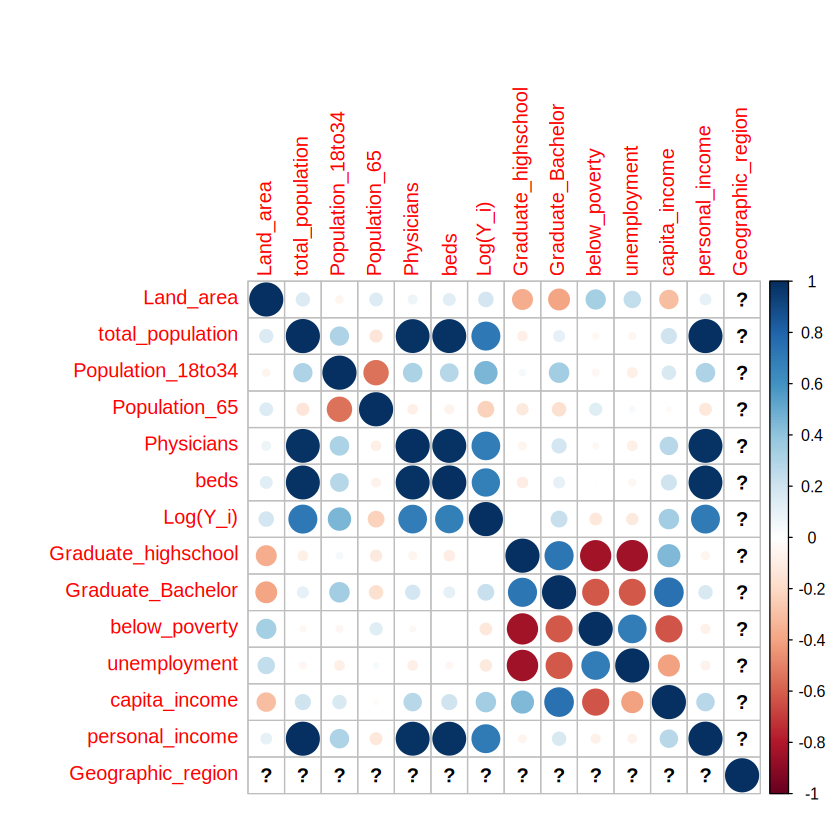

In [ ]:
corrplot(cor(region_4[,4:17])) # see which predictors have the most correlation with response

In [ ]:
# Compute correlation of Log(Y_i) with all numeric predictors
cor_matrix <- cor(region_4[, 4:17], region_4[, "Log(Y_i)"])
cor_matrix

Warning message in cor(region_4[, 4:17], region_4[, "Log(Y_i)"]):
“the standard deviation is zero”


Land_area,0.188824522
total_population,0.712026516
Population_18to34,0.454801589
Population_65,-0.224040331
Physicians,0.697728245
beds,0.680334382
Log(Y_i),1.000000000
Graduate_highschool,0.009896106
Graduate_Bachelor,0.224972104
below_poverty,-0.123239021
unemployment,-0.114807549


In [ ]:
model_r_4 <- lm(`Log(Y_i)` ~ total_population, data = region_4)
summary(model_r_4)
anova(model_r_4)


Call:
lm(formula = `Log(Y_i)` ~ total_population, data = region_4)

Residuals:
     Min       1Q   Median       3Q      Max 
-2.29475 -0.54966  0.02105  0.72703  1.21366 

Coefficients:
                  Estimate Std. Error t value Pr(>|t|)    
(Intercept)      9.465e+00  9.853e-02  96.061  < 2e-16 ***
total_population 7.078e-07  8.059e-08   8.782 3.87e-13 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 0.7606 on 75 degrees of freedom
Multiple R-squared:  0.507,	Adjusted R-squared:  0.5004 
F-statistic: 77.12 on 1 and 75 DF,  p-value: 3.868e-13


,Df,Sum Sq,Mean Sq,F value,Pr(>F)
,<int>,<dbl>,<dbl>,<dbl>,<dbl>
total_population,1,44.61822,44.6182230,77.12419,3.868135e-13
Residuals,75,43.38933,0.5785244,NA,NA


# Regression Fit 4